![Imgur](https://i.imgur.com/A0T6cjl.png)
### [<font size = 2 color="#5890FF">SERIES 1</font>](https://www.kaggle.com/samybaladram/golf-data-analysis-table-of-contents)<font size = 2 color="#7B8698">　‣　D A T A　S C I E N C E　P I P E L I N E　🛠<br></font>[What is Data Science](https://www.kaggle.com/code/samybaladram/01-1-what-is-data-science)・**Data Science Pipeline**<p>
---

# What are the **Steps in Data Science Process?**
![Imgur](https://i.imgur.com/0D06wP7.png)
![Imgur](https://i.imgur.com/0QJ3k1C.png)


# Importance of Data Science Pipeline
![Imgur](https://i.imgur.com/0YZAOnj.png)

# ⛳️  Dataset Introduction: Golf Play Dataset
![Imgur](https://i.imgur.com/HrRXCxf.png)
![Imgur](https://i.imgur.com/HSaTcp4.png)

#  Typical Data Science Pipeline Components
![Imgur](https://i.imgur.com/kr7eCyg.png)

# ⓵ Define Problem
![Imgur](https://i.imgur.com/jYsnrG0.png)

## Know Business Context
![Imgur](https://i.imgur.com/T3kw9ro.png)

## Set Primary Goal
![Imgur](https://i.imgur.com/9Siq2au.png)

## Set Secondary Goal
![Imgur](https://i.imgur.com/ubdTU0b.png)

## Understand Constraints
![Imgur](https://i.imgur.com/PbBrp7y.png)

## Other tasks
![Imgur](https://i.imgur.com/ejN8qKC.png)

# ⓶ Collect and Store Data
![Imgur](https://i.imgur.com/CkCUfpt.png)

## Find Data Sources
![Imgur](https://i.imgur.com/U59k5BX.png)

In [1]:
# In this case, we get it from this kaggle dataset:
# https://www.kaggle.com/datasets/samybaladram/golf-play-extended/data

## Collect the Data
![Imgur](https://i.imgur.com/0XHdKMk.png)

In [2]:
import pandas as pd

path = '/kaggle/input/golf-play-extended/golf_dataset_the_origin.csv'  
df = pd.read_csv(path)

![Imgur](https://i.imgur.com/mJW4YHv.png)

In [3]:
df

,Outlook,Temperature,Humidity,Wind,Play
0,sunny,85.0,85.0,0,0
1,sunny,80.0,90.0,1,0
2,overcast,83.0,78.0,0,1
3,rain,70.0,96.0,0,1
4,rain,68.0,80.0,0,1
5,rain,65.0,70.0,1,0
6,overcast,64.0,65.0,1,1
7,sunny,72.0,95.0,0,0
8,sunny,69.0,70.0,0,1
9,rain,75.0,80.0,0,1


![Imgur](https://i.imgur.com/K681xwj.png)

In [4]:
# The data is automatically saved in csv format in Kaggle repository

# ⓷ Clean & Preprocess Data
![Imgur](https://i.imgur.com/pdfTAXC.png)

## Initial Check
![Imgur](https://i.imgur.com/aI62WBF.png)

In [5]:
# Show the info, including column data types, non-null counts, and memory usage
print("\nInfo:")
print(df.info())

# Show the data types for each column
print("\nData Types:")
print(df.dtypes)

# Show the dimensions (number of rows and columns) of the DataFrame
print("\nDimensions:")
print(df.shape)


Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Outlook      14 non-null     object 
 1   Temperature  14 non-null     float64
 2   Humidity     14 non-null     float64
 3   Wind         14 non-null     int64  
 4   Play         14 non-null     int64  
dtypes: float64(2), int64(2), object(1)
memory usage: 688.0+ bytes
None

Data Types:
Outlook         object
Temperature    float64
Humidity       float64
Wind             int64
Play             int64
dtype: object

Dimensions:
(14, 5)


## Check Missing Values
![Imgur](https://i.imgur.com/Ar1hxXL.png)

In [6]:
# Check for missing values and sum them up for each column
missing_values = df.isna().sum()

# Print the missing value counts
print("Missing Values Count for Each Column:")
print(missing_values)

# Optionally, if you want to see columns where missing values exist
print("\nColumns with Missing Values:")
print(missing_values[missing_values > 0])

Missing Values Count for Each Column:
Outlook        0
Temperature    0
Humidity       0
Wind           0
Play           0
dtype: int64

Columns with Missing Values:
Series([], dtype: int64)


## Check Outliers
![Imgur](https://i.imgur.com/lD9Vbe8.png)

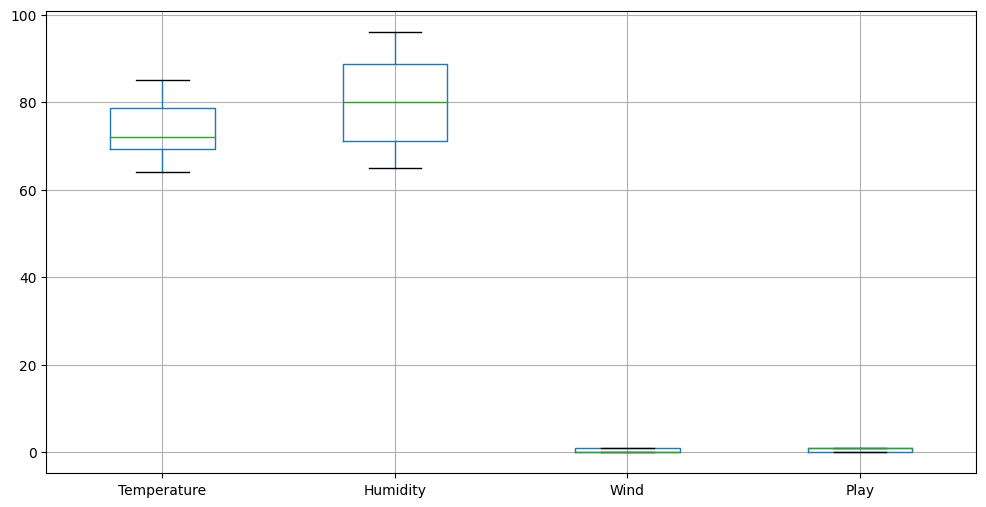

In [7]:
# Boxplot

import matplotlib.pyplot as plt

# Box plot for all numerical features
df.boxplot(figsize=(12, 6))
plt.show()

In [8]:
# Z-score

from scipy import stats
import numpy as np

# Calculate Z-Scores
z_scores = np.abs(stats.zscore(df.select_dtypes(include=[np.number])))

# Get boolean array - True where Z-Score > 3
outliers = (z_scores > 1.6)

# Print  rows containing outliers
print(df[outliers.any(axis=1)])

    Outlook  Temperature  Humidity  Wind  Play
0     sunny         85.0      85.0     0     0
3      rain         70.0      96.0     0     1
6  overcast         64.0      65.0     1     1


## Convert Categories
![Imgur](https://i.imgur.com/IEh5SYU.png)

In [9]:
# Assuming df is your DataFrame and 'Outlook' is the column you want to one-hot encode
dummy_vars = pd.get_dummies(df['Outlook'], prefix='Outlook').astype(int)

# To include these new dummy variables back into the original DataFrame, you can use concat
df_concat = pd.concat([dummy_vars, df], axis=1)

# Optionally, drop the original 'Outlook' column (if you don't need it anymore)
df_concat.drop('Outlook', axis=1, inplace=True)

# Display the DataFrame to check the new dummy variables
print(df_concat)

    Outlook_overcast  Outlook_rain  Outlook_sunny  Temperature  Humidity  \
0                  0             0              1         85.0      85.0   
1                  0             0              1         80.0      90.0   
2                  1             0              0         83.0      78.0   
3                  0             1              0         70.0      96.0   
4                  0             1              0         68.0      80.0   
5                  0             1              0         65.0      70.0   
6                  1             0              0         64.0      65.0   
7                  0             0              1         72.0      95.0   
8                  0             0              1         69.0      70.0   
9                  0             1              0         75.0      80.0   
10                 0             0              1         75.0      70.0   
11                 1             0              0         72.0      90.0   
12          

## Standardize Numbers
![Imgur](https://i.imgur.com/vMcY6SA.png)

In [10]:
from sklearn.preprocessing import StandardScaler

# Create a StandardScaler object
scaler = StandardScaler()

# Fit and transform the columns
scaled_values = scaler.fit_transform(df_concat[['Temperature', 'Humidity']]).round(2)

# Replace original columns with scaled ones
df_concat[['Temperature', 'Humidity']] = scaled_values

# Display the DataFrame to check the standardized columns
print(df_concat)

    Outlook_overcast  Outlook_rain  Outlook_sunny  Temperature  Humidity  \
0                  0             0              1         1.80      0.50   
1                  0             0              1         1.02      1.02   
2                  1             0              0         1.49     -0.24   
3                  0             1              0        -0.56      1.66   
4                  0             1              0        -0.88     -0.03   
5                  0             1              0        -1.35     -1.08   
6                  1             0              0        -1.51     -1.61   
7                  0             0              1        -0.25      1.55   
8                  0             0              1        -0.72     -1.08   
9                  0             1              0         0.23     -0.03   
10                 0             0              1         0.23     -1.08   
11                 1             0              0        -0.25      1.02   
12          

## Select Features
![Imgur](https://i.imgur.com/82Ik92O.png)

In [11]:
# All columns seems usable and clean!

# ⓸ Explore Data
![Imgur](https://i.imgur.com/GQMJMjq.png)

## Compute Descriptive Statistics
![Imgur](https://i.imgur.com/TzmGgOO.png)

In [12]:
df.describe()

,Temperature,Humidity,Wind,Play
count,14.000000,14.000000,14.000000,14.000000
mean,73.571429,80.285714,0.428571,0.642857
std,6.571667,9.840486,0.513553,0.497245
min,64.000000,65.000000,0.000000,0.000000
25%,69.250000,71.250000,0.000000,0.000000
50%,72.000000,80.000000,0.000000,1.000000
75%,78.750000,88.750000,1.000000,1.000000
max,85.000000,96.000000,1.000000,1.000000


## Examine Data Distributions
![Imgur](https://i.imgur.com/ncDyeEu.png)

In [13]:
# coming soon

## Find relationships between features
![Imgur](https://i.imgur.com/SpYVjqH.png)

In [14]:
# coming soon

## Explore categorical data
![Imgur](https://i.imgur.com/kbUnhyg.png)

In [15]:
# coming soon

## ⓹ Train Model
![Imgur](https://i.imgur.com/X33hk6B.png)

## Choose the Algorithm
![Imgur](https://i.imgur.com/rVy0Qb4.png)

In [16]:
# coming soon

## Use Feature Selection Algorithms
![Imgur](https://i.imgur.com/tB7SYzB.png)

In [17]:
# coming soon

## Split the Data

![Imgur](https://i.imgur.com/CeCT6vP.png)

In [18]:
# coming soon

## Train the Algorithm
![Imgur](https://i.imgur.com/AbGFWY6.png)

In [19]:
# coming soon

# ⓺ Evaluate & Interpret Model
![Imgur](https://i.imgur.com/PuUVKFu.png)

## Select Evaluation Metric
![Imgur](https://i.imgur.com/VItG3Zm.png)

In [20]:
# coming soon

## Test Data
![Imgur](https://i.imgur.com/2jlq4Xi.png)

In [21]:
# coming soon

## Evaluate the Model
![Imgur](https://i.imgur.com/NJDCn2m.png)

In [22]:
# coming soon

## Interpret the Result
![Imgur](https://i.imgur.com/kiqxSf2.png)

In [23]:
# coming soon

## Perform Cross-validation
![Imgur](https://i.imgur.com/qDVxpHe.png)

In [24]:
# coming soon

## Tune the Model 
![Imgur](https://i.imgur.com/9mBU3rC.png)

In [25]:
# coming soon

## Repeat the Training Process
![Imgur](https://i.imgur.com/dSgVPyf.png)

In [26]:
# coming soon

## Compare with Other Models
![Imgur](https://i.imgur.com/ViXoVuz.png)

In [27]:
# coming soon

# ⓻ Deploy & Monitor
![Imgur](https://i.imgur.com/nebmsbn.png)

## Choose Deployment Method
![Imgur](https://i.imgur.com/i86wCVx.png)

## Other tasks
![Imgur](https://i.imgur.com/DHI5DgU.png)

![Imgur](https://i.imgur.com/M0mwv0l.png)
### [<font size = 2 color="#5890FF">SERIES 1</font>](https://www.kaggle.com/samybaladram/golf-data-analysis-table-of-contents)<font size = 2 color="#7B8698">　‣　D A T A　S C I E N C E　P I P E L I N E　🛠<br></font>[What is Data Science](https://www.kaggle.com/code/samybaladram/01-1-what-is-data-science)・**Data Science Pipeline**<p>

--- 

*Explore [diverse notebooks full of captivating visuals](https://www.kaggle.com/samybaladram/golf-data-analysis-table-of-contents), each tackling unique facets of the field—all based on some mini, yet enriching, golf play datasets. Your hole-in-one guide to mastering Data Science basics.*


### For a complete list of topics and series, see [⛳️ 📋 Data Science with Golf Dataset・Table of Contents](https://www.kaggle.com/samybaladram/golf-data-analysis-table-of-contents).
---

**Your Feedback Matters! 🍃** If you find this notebook series useful, an ⬆️ *upvote* would be appreciated to help others in the community discover it too!